<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter6/pendulum_jumping_cases_1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Parametric Pumping and Active Damping of a pendulum via a jumping bug.

Simulating Parametric Pumping...
Simulating Active Damping...


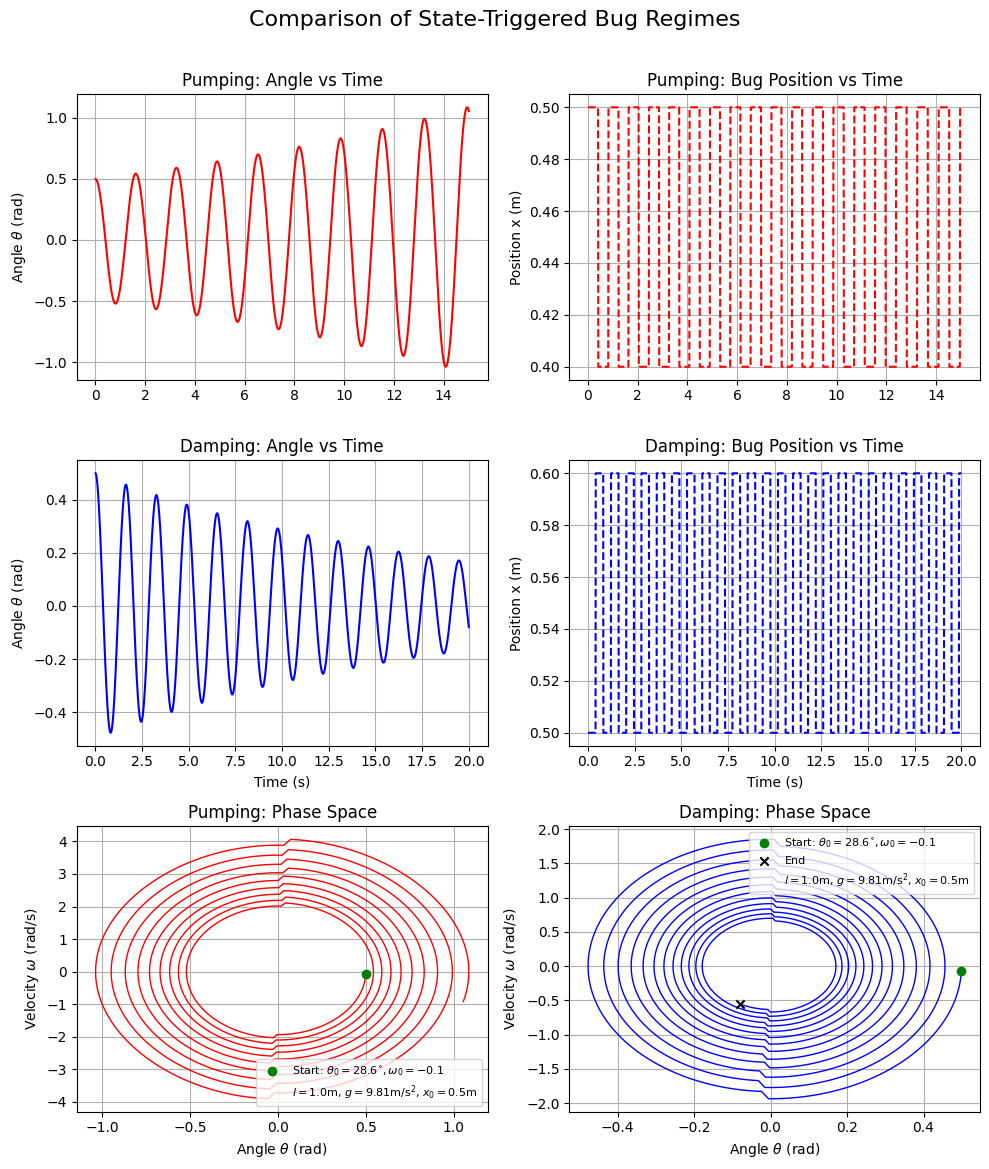

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

m = 1.0       # Mass of the rod (kg)
l = 1.0       # Length of the rod (m)
m_b = 0.2     # Mass of the bug (kg)
g = 9.81      # Gravity (m/s^2)
delta_x = 0.1 # Distance of a single jump step (m)

def rod_derivatives(t, state, x_n):
    """
    Differential equation for the continuous flow between jumps.
    x_n is constant during this phase.
    """
    theta, omega = state
    I_current = (1/3) * m * l**2 + m_b * x_n**2
    kappa_current = g * (m * l / 2 + m_b * x_n)
    alpha = -(kappa_current / I_current) * np.sin(theta)
    return [omega, alpha]

def simulate_regime(regime, t_max=15.0, dt_integrate=0.01):
    """
    Simulates the chosen regime using an event-driven loop with zero-crossing detection.
    """
    theta_0 = np.radians(28.6)    # Start with a moderate swing (~0.5 radians)
    omega_0 = 0.0
    x_0 = l / 2      # Bug starts in the middle

    current_time = 0.0
    current_state = [theta_0, omega_0]
    current_x = x_0

    times, thetas, omegas, x_positions = [], [], [], []

    while current_time < t_max:
        # Capture state before integration for zero-crossing detection
        prev_theta, prev_omega = current_state

        # Integrate forward by a small step
        t_span = (current_time, current_time + dt_integrate)
        sol = solve_ivp(rod_derivatives, t_span, current_state,
                        args=(current_x,), rtol=1e-6, atol=1e-8)

        # Store results
        times.append(sol.t[-1])
        thetas.append(sol.y[0][-1])
        omegas.append(sol.y[1][-1])
        x_positions.append(current_x)

        current_time = sol.t[-1]
        curr_theta = sol.y[0][-1]
        curr_omega = sol.y[1][-1]
        current_state = [curr_theta, curr_omega]

        # Check Triggers for the specific regime using Zero-Crossing Detection
        jump_occurred = False
        new_x = current_x

        # Zero-crossing logic: True if the sign flipped or hit exactly zero from a non-zero value
        apex_crossed = (prev_omega > 0 and curr_omega <= 0) or (prev_omega < 0 and curr_omega >= 0)
        bottom_crossed = (prev_theta > 0 and curr_theta <= 0) or (prev_theta < 0 and curr_theta >= 0)

        if regime == "pumping":
            if apex_crossed and current_x < l: # Apex -> Outward
                new_x = min(current_x + delta_x, l)
                jump_occurred = True
            elif bottom_crossed and current_x > 0: # Bottom -> Inward
                new_x = max(current_x - delta_x, 0)
                jump_occurred = True

        elif regime == "damping":
            if apex_crossed and current_x > 0: # Apex -> Inward
                new_x = max(current_x - delta_x, 0)
                jump_occurred = True
            elif bottom_crossed and current_x < l: # Bottom -> Outward
                new_x = min(current_x + delta_x, l)
                jump_occurred = True

        # Apply the Discrete Map if a jump happened
        if jump_occurred and new_x != current_x:
            I_old = (1/3) * m * l**2 + m_b * current_x**2
            I_new = (1/3) * m * l**2 + m_b * new_x**2

            # Conservation of angular momentum
            new_omega = current_state[1] * (I_old / I_new)
            current_state[1] = new_omega
            current_x = new_x

    return np.array(times), np.array(thetas), np.array(omegas), np.array(x_positions)

# ==========================================
# SIMULATION & PLOTTING (Notebook Ready)
# ==========================================
print("Simulating Parametric Pumping...")
t_pump, th_pump, om_pump, x_pump = simulate_regime("pumping", t_max=15.0)

print("Simulating Active Damping...")
t_damp, th_damp, om_damp, x_damp = simulate_regime("damping", t_max=20.0)

# Create a 3x2 grid of plots for better page fit
fig, axs = plt.subplots(3, 2, figsize=(10, 12))
fig.suptitle("Comparison of State-Triggered Bug Regimes", fontsize=16, y=0.97)

param_label = f'$l={l}$m, $g={g}$m/s$^2$, $x_0={l/2}$m'

# ---------------------------------------------------------
# ROW 1: PUMPING TIME SERIES
# ---------------------------------------------------------
axs[0, 0].plot(t_pump, th_pump, color='red')
axs[0, 0].set_title("Pumping: Angle vs Time")
axs[0, 0].set_ylabel(r"Angle $\theta$ (rad)")
axs[0, 0].grid(True)

axs[0, 1].plot(t_pump, x_pump, color='red', linestyle='--')
axs[0, 1].set_title("Pumping: Bug Position vs Time")
axs[0, 1].set_ylabel("Position x (m)")
axs[0, 1].grid(True)

# ---------------------------------------------------------
# ROW 2: DAMPING TIME SERIES
# ---------------------------------------------------------
axs[1, 0].plot(t_damp, th_damp, color='blue')
axs[1, 0].set_title("Damping: Angle vs Time")
axs[1, 0].set_ylabel(r"Angle $\theta$ (rad)")
axs[1, 0].set_xlabel("Time (s)")
axs[1, 0].grid(True)

axs[1, 1].plot(t_damp, x_damp, color='blue', linestyle='--')
axs[1, 1].set_title("Damping: Bug Position vs Time")
axs[1, 1].set_ylabel("Position x (m)")
axs[1, 1].set_xlabel("Time (s)")
axs[1, 1].grid(True)

# ---------------------------------------------------------
# ROW 3: PHASE SPACES
# ---------------------------------------------------------
# Pumping Phase Space
axs[2, 0].plot(th_pump, om_pump, color='red', linewidth=1)
axs[2, 0].scatter([th_pump[0]], [om_pump[0]], color='green', zorder=5, label=f'Start: $\\theta_0={np.degrees(th_pump[0]):.1f}^{{\\circ}}, \\omega_0={om_pump[0]:.1f}$')
axs[2, 0].plot([], [], ' ', label=param_label)
axs[2, 0].set_title("Pumping: Phase Space")
axs[2, 0].set_xlabel(r"Angle $\theta$ (rad)")
axs[2, 0].set_ylabel(r"Velocity $\omega$ (rad/s)")
axs[2, 0].legend(loc='lower right', fontsize=8)
axs[2, 0].grid(True)

# Damping Phase Space
axs[2, 1].plot(th_damp, om_damp, color='blue', linewidth=1)
axs[2, 1].scatter([th_damp[0]], [om_damp[0]], color='green', zorder=5, label=f'Start: $\\theta_0={np.degrees(th_damp[0]):.1f}^{{\\circ}}, \\omega_0={om_damp[0]:.1f}$')
axs[2, 1].scatter([th_damp[-1]], [om_damp[-1]], color='black', marker='x', zorder=5, label='End')
axs[2, 1].plot([], [], ' ', label=param_label)
axs[2, 1].set_title("Damping: Phase Space")
axs[2, 1].set_xlabel(r"Angle $\theta$ (rad)")
axs[2, 1].set_ylabel(r"Velocity $\omega$ (rad/s)")
axs[2, 1].legend(loc='upper right', fontsize=8)
axs[2, 1].grid(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()